<p align='center'><img src='../assets/logo_team.png' width='140'></p>

<h1 style="color:#F5C542; font-family:'Playfair Display',Georgia,serif; border-bottom:2px solid #D4A017; padding-bottom:6px;">Exercice VI · Marché concurrentiel</h1>

Trois assureurs tarifent la garantie DDE avec des modèles fréquence × coût de plus en plus segmentés.
Prime commerciale = prime pure × (1 + marge). Sur la base test, chaque assuré choisit l'assureur le moins cher.

| | Assureur 1 | Assureur 2 | Assureur 3 |
|---|---|---|---|
| Variables | aucune | Nbpieces, Nbpers, Qualite | Nbpieces, Nbpers, Qualite, Local |
| Marge | 30 % | 15 % | 15 % |

In [1]:
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
from IPython.display import display

from src import theme as T, graphiques as GR
from src.data import *
from src.indicateurs import *
from src import modeles as M
print("Rendu :", T.configurer_notebook())
pd.options.display.float_format = "{:,.4f}".format

from src.marche import simuler_marche, marge_optimale

Rendu : plotly_mimetype+notebook_connected+png


In [2]:
bd = charger_base()                                  # base complète (1 112 095 lignes)
bda, bdt, samp = decouper(bd, seed=2016)             # np.random.seed(2016) ; np.random.choice(len(bd), 300000)
print(f"Base : {bd.shape} · apprentissage : {len(bda):,} · test : {len(bdt):,}")

bdc = base_cout(bda, 'DDE')

Base : (1112095, 24) · apprentissage : 300,000 · test : 812,095


In [3]:
assureurs = {"Assureur 1": [], "Assureur 2": ["Nbpieces", "Nbpers", "Qualite"],
             "Assureur 3": ["Nbpieces", "Nbpers", "Qualite", "Local"]}
marges = {"Assureur 1": 0.30, "Assureur 2": 0.15, "Assureur 3": 0.15}
pp = {}
for nom, vs in assureurs.items():
    ff, fc = M.glm_freq(bda, vs), M.glm_cout(bdc, vs)
    pp[nom] = M.prime_pure(ff, fc, bdt).to_numpy()
    print(f"{nom} : charge prédite apprentissage / observée = {M.prime_pure(ff, fc, bda).sum() / bda['Cout_DDE'].sum():.4f}")
cout = bdt["Cout_DDE"].to_numpy()

Assureur 1 : charge prédite apprentissage / observée = 1.0000


Assureur 2 : charge prédite apprentissage / observée = 1.0002


Assureur 3 : charge prédite apprentissage / observée = 0.9992


<h3 style="color:#F5C542; font-family:'Playfair Display',Georgia,serif; border-bottom:2px solid #D4A017; padding-bottom:6px;">Question 0 · Chaque assureur seul sur le marché</h3>

In [4]:
sim = simuler_marche(pp, marges, cout, bdt[["Local", "Nbpieces"]])
syn = sim["synthese"]
display(syn[["Assureur", "Marge", "Résultat seul", "S/P seul"]].style.format({"Marge": "{:.0%}", "Résultat seul": "{:,.0f} €", "S/P seul": "{:.1%}"}))

,Assureur,Marge,Résultat seul,S/P seul
0,Assureur 1,30%,"6,002,517 €",76.8%
1,Assureur 2,15%,"3,032,043 €",86.8%
2,Assureur 3,15%,"3,005,491 €",86.9%


<div style="border-left:4px solid #D4A017; background:#062A58; color:#EAF0FF; padding:12px 16px; border-radius:0 10px 10px 0;"><b style="color:#F5C542">Lecture actuarielle.</b> Seul sur le marché, chaque assureur encaisse la prime de tous les assurés. Ses primes pures étant calibrées en moyenne, son résultat est proche de la marge appliquée : l'assureur 1 (30 %) serait le plus rentable. Sans concurrence, la segmentation ne rapporte rien.</div>

<h3 style="color:#F5C542; font-family:'Playfair Display',Georgia,serif; border-bottom:2px solid #D4A017; padding-bottom:6px;">Question 1 · Marché concurrentiel</h3>

,Assureur,Marge,Nb contrats,Part de marché,Primes encaissées,Sinistres payés,Résultat,S/P,Prime moyenne,Résultat seul,S/P seul
0,Assureur 1,30%,"193,032",23.8%,"5,999,663 €","7,735,998 €","-1,736,335 €",128.9%,31.08 €,"6,002,517 €",76.8%
1,Assureur 2,15%,"307,084",37.8%,"5,413,220 €","5,731,259 €","-318,039 €",105.9%,17.63 €,"3,032,043 €",86.8%
2,Assureur 3,15%,"311,979",38.4%,"7,414,020 €","6,385,657 €","1,028,362 €",86.1%,23.76 €,"3,005,491 €",86.9%


col_0,Dernier,Inter-1-2-3,Inter-4+,Maison,Rdc
Assureur,,,,,
Assureur 1,2.7%,6.3%,5.4%,82.3%,3.4%
Assureur 2,6.4%,39.3%,31.3%,0.0%,23.0%
Assureur 3,8.9%,0.0%,0.0%,91.1%,0.0%


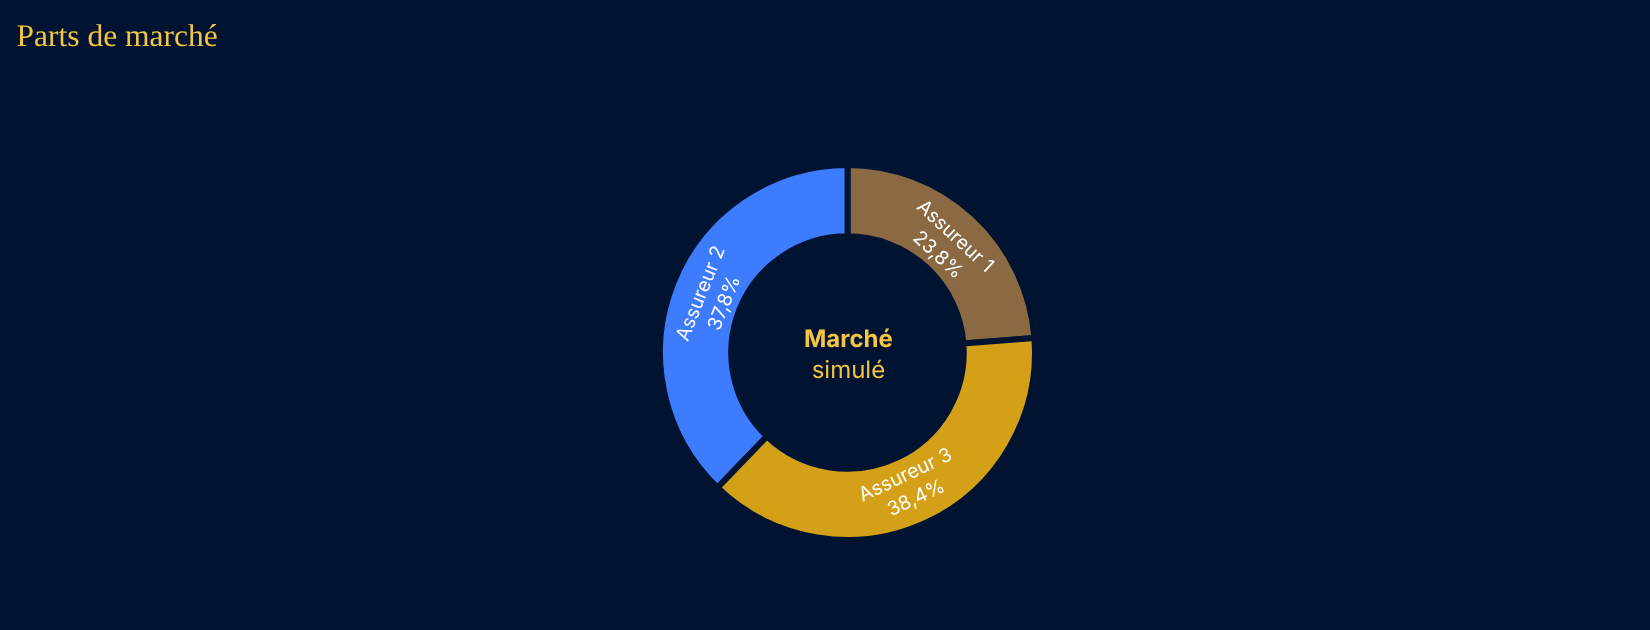

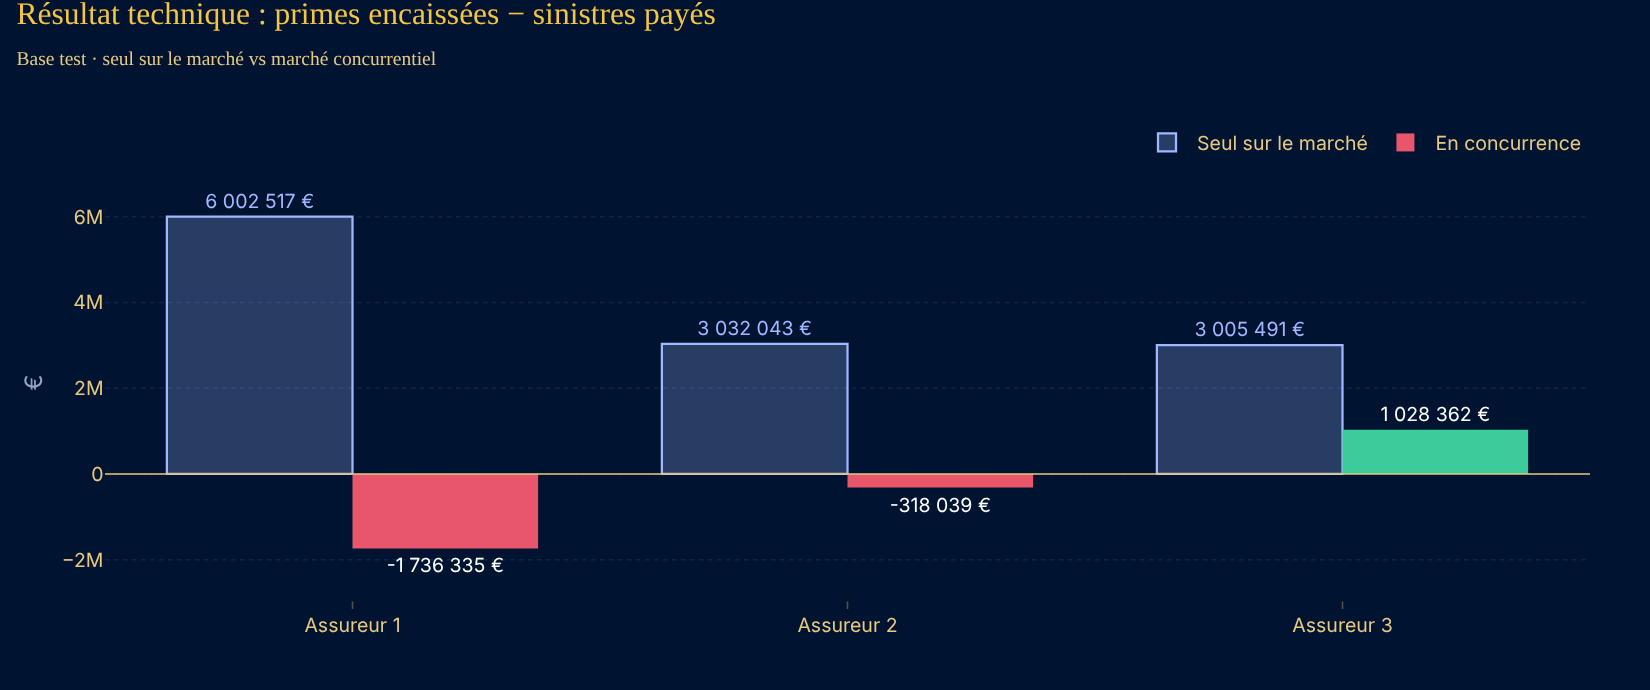

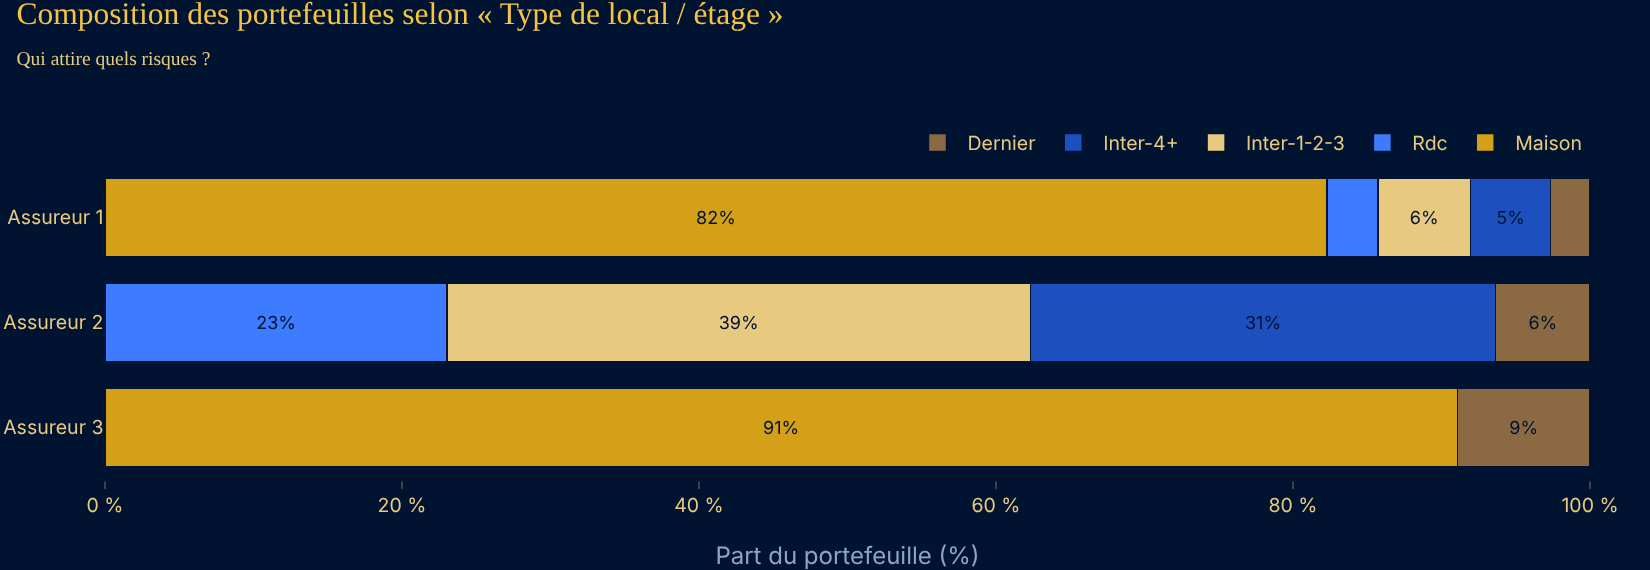

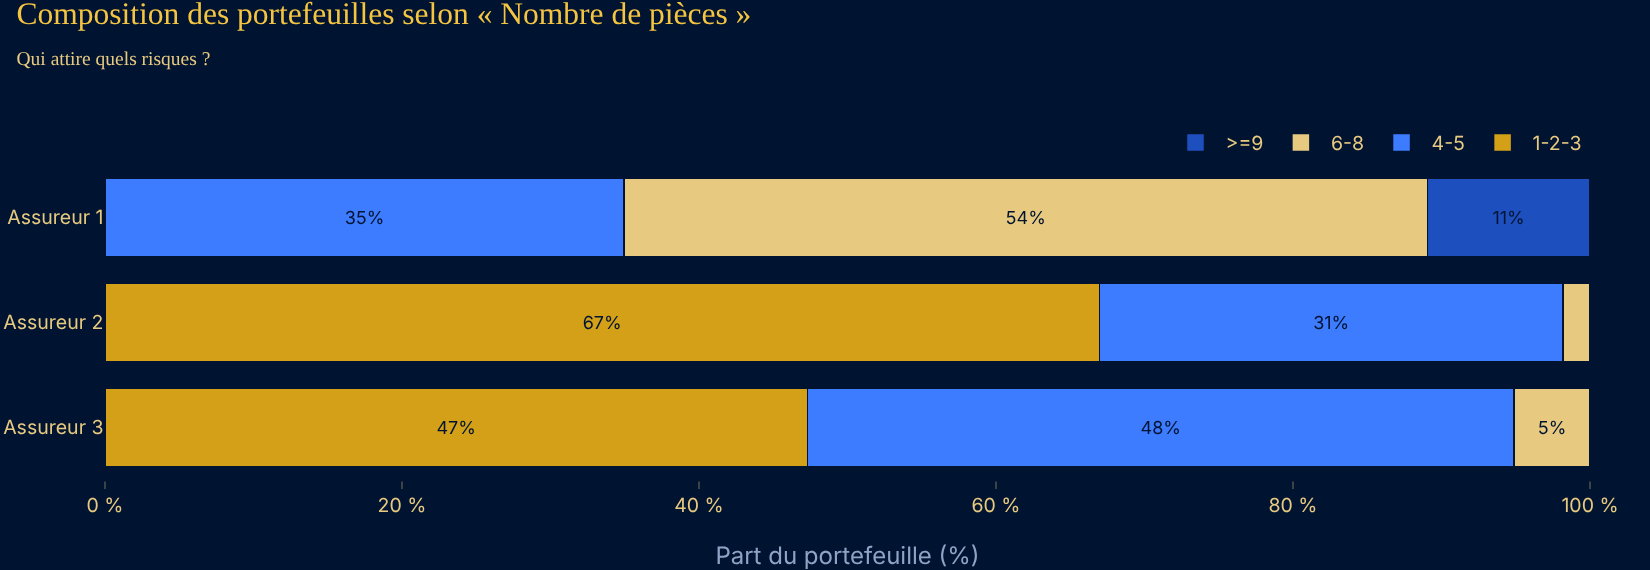

In [5]:
display(syn.style.format({"Marge": "{:.0%}", "Nb contrats": "{:,.0f}", "Part de marché": "{:.1%}",
                          "Primes encaissées": "{:,.0f} €", "Sinistres payés": "{:,.0f} €", "Résultat": "{:,.0f} €",
                          "S/P": "{:.1%}", "Prime moyenne": "{:,.2f} €", "Résultat seul": "{:,.0f} €", "S/P seul": "{:.1%}"}))
display(sim["repartitions"]["Local"].style.format("{:.1%}"))
GR.parts_de_marche(syn.set_index("Assureur")["Part de marché"].to_dict()).show()
GR.resultats_assureurs(syn.set_index("Assureur")["Résultat seul"].to_dict(), syn.set_index("Assureur")["Résultat"].to_dict()).show()
GR.repartition_variable(sim["repartitions"]["Local"], "Local").show()
GR.repartition_variable(sim["repartitions"]["Nbpieces"], "Nbpieces").show()

<h3 style="color:#F5C542; font-family:'Playfair Display',Georgia,serif; border-bottom:2px solid #D4A017; padding-bottom:6px;">Question 2 · L'antisélection</h3>

<div style="border-left:4px solid #D4A017; background:#062A58; color:#EAF0FF; padding:12px 16px; border-radius:0 10px 10px 0;"><b style="color:#F5C542">Lecture actuarielle.</b> L'**antisélection** apparaît lorsque l'assureur ne peut pas distinguer les risques aussi bien que l'assuré ou que ses
concurrents : il attire alors ceux qu'il sous-tarife. En marché concurrentiel, l'assuré compare les prix et choisit le
moins cher ; un assureur moins segmenté que ses concurrents se voit laisser les risques pour lesquels son prix moyen
est inférieur au vrai coût, et perd les bons risques auxquels il demande trop. Son ratio S/P se dégrade, il augmente
ses prix, perd encore ses meilleurs clients : c'est la spirale de l'antisélection.</div>

<h3 style="color:#F5C542; font-family:'Playfair Display',Georgia,serif; border-bottom:2px solid #D4A017; padding-bottom:6px;">Question 3 · Interprétation, à la lumière de l'analyse univariée de Local</h3>

,Local,Part expo,Fréquence,Coût moyen,Prime pure
0,Maison,59.3%,1.51%,"1,660 €",25.06 €
1,Rdc,8.6%,1.98%,"1,033 €",20.45 €
2,Inter-1-2-3,15.1%,2.20%,977 €,21.49 €
3,Inter-4+,11.5%,2.26%,900 €,20.32 €
4,Dernier,5.4%,1.90%,950 €,18.02 €


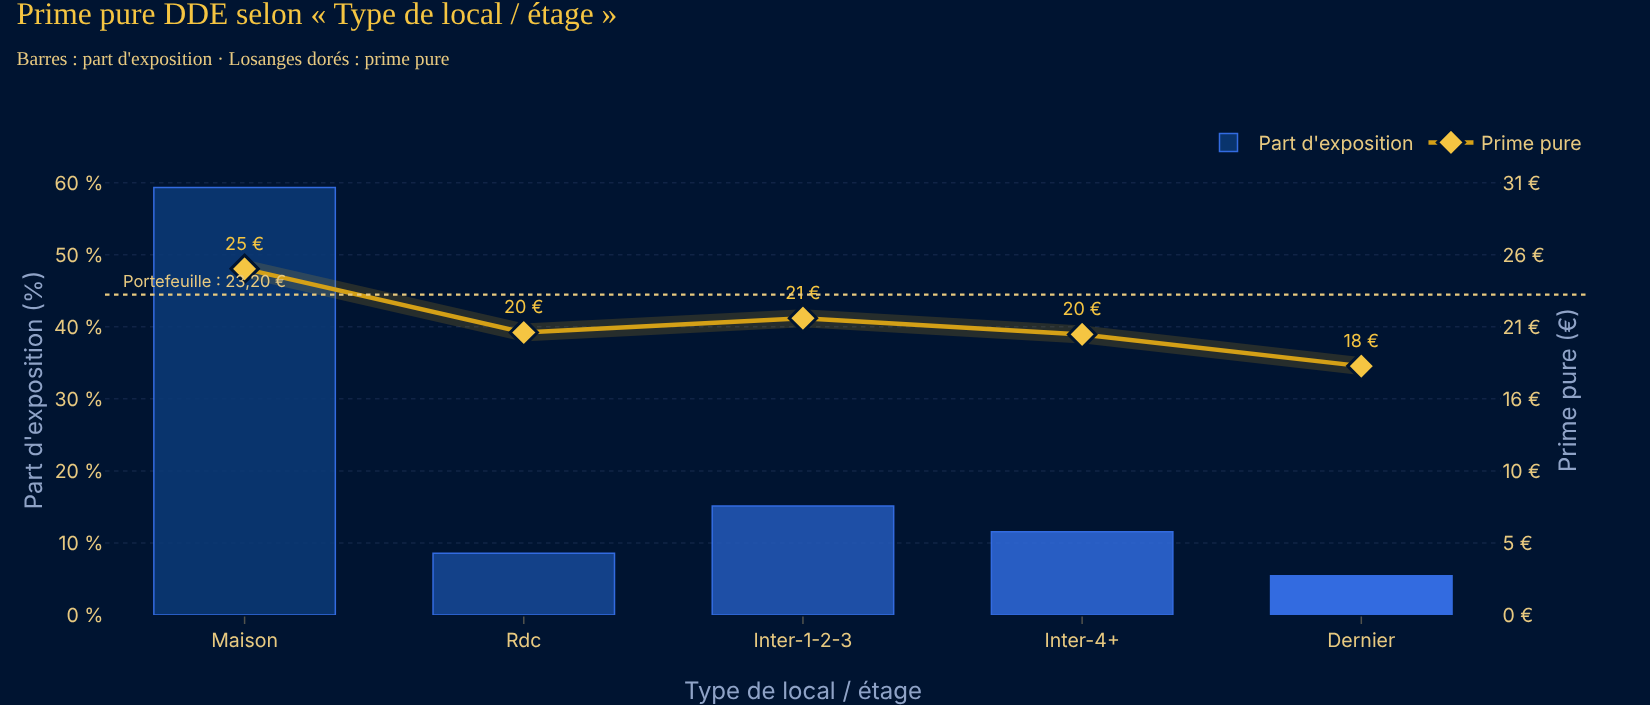

In [6]:
t = table_indicateurs(bd, "Local")
display(t[["Local", "Part expo", "Fréquence", "Coût moyen", "Prime pure"]].style.format(
    {"Part expo": "{:.1%}", "Fréquence": "{:.2%}", "Coût moyen": "{:,.0f} €", "Prime pure": "{:,.2f} €"}))
GR.univarie(t, "Local", "DDE", "Prime pure").show()

<div style="border-left:4px solid #D4A017; background:#062A58; color:#EAF0FF; padding:12px 16px; border-radius:0 10px 10px 0;"><b style="color:#F5C542">Lecture actuarielle.</b> L'analyse univariée de Local montre que les **maisons** (59 % de l'exposition) ont la **fréquence la plus basse**
(1,51 % contre 1,9 à 2,3 % pour les appartements) mais le coût moyen le plus élevé (1 660 € contre 900 à 1 030 €).
Leur prime pure brute paraît plus élevée (25 € contre 18 à 21 €), mais c'est un effet de structure : les maisons sont
grandes et habitées par des propriétaires, deux facteurs aggravants. **À taille, composition et qualité égales**, le
GLM de l'assureur 3 trouve une maison environ **20 % moins risquée** qu'un appartement (fréquence divisée par ≈ 1,8,
coût multiplié par ≈ 1,4). L'assureur 2 ignore Local : il moyenne maisons et appartements, donc **surtarife les maisons
et sous-tarife les appartements**. Résultat : l'assureur 3 capte les maisons (91 % de son portefeuille), l'assureur 2
ne garde que des appartements (0 % de maisons) qu'il tarife trop bas, d'où un S/P de 106 % et une perte malgré une
marge identique. L'assureur 1, sans aucune variable et avec 30 % de marge, ne gagne que les profils dont le risque
dépasse son prix moyen (surtout les grandes maisons de propriétaires) : S/P de 129 %, c'est lui qui subit le plus
l'antisélection. Plus un assureur segmente finement, mieux il résiste.</div>

<h3 style="color:#F5C542; font-family:'Playfair Display',Georgia,serif; border-bottom:2px solid #D4A017; padding-bottom:6px;">Question 4 · Marge optimale de l'assureur 3</h3>

Marge optimale au % près : 19% · résultat 1,282,603 €
Affinage (pas de 0,05 %) : 19.90% · résultat 1,339,229 €


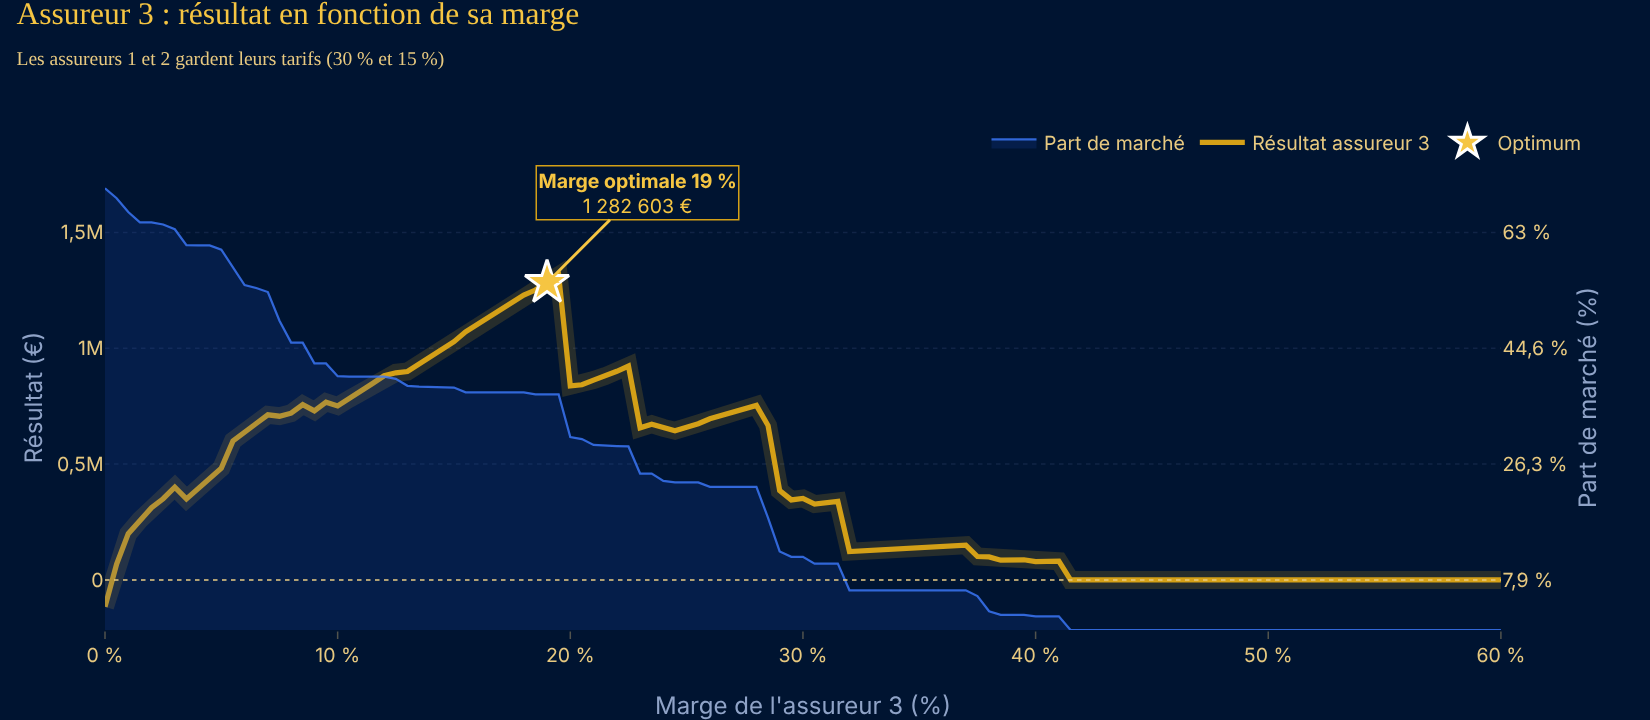

In [7]:
opt = marge_optimale(2, pp, marges, cout, bornes=(0.0, 0.6))
print(f"Marge optimale au % près : {opt['marge_au_pct']:.0%} · résultat {opt['resultat_au_pct']:,.0f} €")
print(f"Affinage (pas de 0,05 %) : {opt['marge_fine']:.2%} · résultat {opt['resultat_fin']:,.0f} €")
from src.marche import balayage_marge
g = np.arange(0, 0.6001, 0.005)
r, p = balayage_marge(2, pp, marges, cout, g)
GR.courbe_marge(g, r, p, (opt["marge_au_pct"], opt["resultat_au_pct"])).show()

<div style="border-left:4px solid #D4A017; background:#062A58; color:#EAF0FF; padding:12px 16px; border-radius:0 10px 10px 0;"><b style="color:#F5C542">Lecture actuarielle.</b> Le résultat de l'assureur 3 est une fonction en escalier de sa marge : chaque hausse augmente la prime unitaire mais
fait basculer des segments chez l'assureur 2. L'optimum réalise le meilleur compromis prix × volume ; au-delà,
l'assureur passe au-dessus du concurrent sur des segments entiers et son résultat chute. Comme la fonction est
discontinue, on utilise une recherche sur grille plutôt qu'un optimiseur continu (le `minimize_scalar` du corrigé peut
s'arrêter sur un optimum local). Hypothèse forte : les concurrents ne réagissent pas.</div>